# Data cleaning and tyding

Initialize the environment by importing the required libraries and loading the primary dataset

In [437]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from plotnine import aes, ggplot, labs, geom_boxplot, geom_col, scale_fill_manual, theme_minimal, scale_fill_brewer, geom_text, position_stack

df = pd.read_csv("dataset.csv")

original_shape = df.shape
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Rows: 9255
Columns: 25


Just to have an idea of what our dataset contains, here there are all the columns with their type and non null count.

In [438]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9255 entries, 0 to 9254
Data columns (total 25 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       9255 non-null   float64
 1   sex       9255 non-null   str    
 2   num.co    9255 non-null   int64  
 3   diabetes  9255 non-null   int64  
 4   dementia  9255 non-null   int64  
 5   meanbp    9254 non-null   float64
 6   hrt       9254 non-null   float64
 7   resp      9254 non-null   float64
 8   temp      9254 non-null   float64
 9   crea      9188 non-null   float64
 10  sod       9254 non-null   float64
 11  adlsc     9255 non-null   float64
 12  hday      9255 non-null   int64  
 13  ca        9255 non-null   str    
 14  scoma     9254 non-null   float64
 15  dzgroup   9255 non-null   str    
 16  aps       9254 non-null   float64
 17  glucose   4442 non-null   float64
 18  bun       4829 non-null   float64
 19  alb       5094 non-null   float64
 20  prg6m     7591 non-null   float64
 21  in

### Convert categorical columns

In [439]:
df["sex"] = pd.Categorical(
    df["sex"],
    categories = ["male","female"],
    ordered = False
)

df["ca"] = pd.Categorical(
    df["ca"],
    categories = ["no","yes","metastatic"],
    ordered = False
)

df["income"] = pd.Categorical(
    df["income"],
    categories = ["under $11k", "$11-$25k", "$25-$50k", ">$50k"],
    ordered = True
)

C:\Users\matte\AppData\Local\Temp\ipykernel_27740\865691590.py:1: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.


### View of variables distributions

To provide a compact overview of the dataset, we inspect the distribution of both numerical and categorical variables.

For numerical variables, we report standard descriptive statistics.  
For categorical variables, we report the frequency of each category, so that the composition of the dataset is clear before cleaning decisions are finalized.

In [440]:
df.describe(include="number")

,age,num.co,diabetes,dementia,meanbp,hrt,resp,temp,crea,sod,adlsc,hday,scoma,aps,glucose,bun,alb,prg6m,death,charges
count,9255.000000,9255.000000,9255.000000,9255.000000,9254.000000,9254.000000,9254.000000,9254.000000,9188.000000,9254.000000,9255.000000,9255.000000,9254.000000,9254.000000,4442.000000,4829.000000,5094.000000,7591.000000,9255.000000,9.079000e+03
mean,62.609125,1.866883,0.194706,0.032739,84.521126,97.205068,23.343635,37.107137,1.768102,137.556732,1.888078,4.414155,12.103631,37.588178,159.581720,32.335266,2.947362,0.499841,0.679633,6.029155e+04
std,15.608661,1.344730,0.395995,0.177962,27.704806,31.568357,9.584817,1.253363,1.680541,6.049489,2.004974,9.122213,24.661683,19.893077,88.260602,26.738338,0.881670,0.304525,0.466643,1.032249e+05
min,18.041990,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,31.699220,0.099991,110.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.399963,0.000000,0.000000,1.169000e+03
25%,52.719970,1.000000,0.000000,0.000000,63.000000,72.000000,18.000000,36.195310,0.899902,134.000000,0.000000,1.000000,0.000000,23.000000,102.000000,14.000000,2.399902,0.200000,0.000000,9.772972e+03
50%,64.834960,2.000000,0.000000,0.000000,77.000000,100.000000,24.000000,36.695310,1.199951,137.000000,1.000000,1.000000,0.000000,34.000000,135.000000,23.000000,2.899902,0.500000,1.000000,2.506800e+04
75%,73.983490,3.000000,0.000000,0.000000,107.000000,120.000000,28.000000,38.195310,1.899902,141.000000,3.000000,3.000000,9.000000,49.000000,188.000000,42.000000,3.599609,0.750000,1.000000,6.496900e+04
max,101.847960,9.000000,1.000000,1.000000,195.000000,300.000000,90.000000,41.695310,21.500000,181.000000,7.073242,148.000000,100.000000,143.000000,1092.000000,300.000000,29.000000,1.000000,1.000000,1.435423e+06


The table above summarizes the main numerical variables through quartiles, central tendency and dispersion. This helps us detect variables with unusual spread, strong skewness or suspicious ranges that may require additional validation during the cleaning stage.

In [441]:
categorical_cols = df.select_dtypes(include=["category"]).columns

for col in categorical_cols:
    print(f"\nDistribution of {col}")
    display(
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="count")
    )


Distribution of sex


,sex,count
0,male,4948
1,female,3846
2,NaN,461



Distribution of ca


,ca,count
0,no,6100
1,metastatic,1882
2,yes,1273



Distribution of income


,income,count
0,NaN,3028
1,under $11k,2902
2,$11-$25k,1550
3,$25-$50k,1081
4,>$50k,694


In particular we look at the positive rate of the target variable `death`:

In [442]:
positive_rate = (df["death"].astype(int).sum() / df.shape[0]) * 100
print(f"The positive rate of death in the cleaned dataset is: {positive_rate:.2f}%")

The positive rate of death in the cleaned dataset is: 67.96%


We note that several variables listed in the project specifications are not actually present in the provided dataset. Therefore, we will work with the columns available in the file we received. Among these, `sfdm2` appears in the dataset but is not described in the project specifications and we don't know what it represents, so we remove it.

In [443]:
df = df.drop(columns=["sfdm2"])

We check the number of duplicated rows, and remove them

In [444]:
print("Number of duplicated rows:", df.duplicated().sum())
df = df.drop_duplicates()
print(f"Lenght of dataset without duplicates:{df.shape[0]}")

Number of duplicated rows: 150
Lenght of dataset without duplicates:9105


We check for missing values and calculate missing percentages for each column

In [445]:
string_cols = df.select_dtypes(include="string").columns
df[string_cols] = df[string_cols].apply(lambda col: col.str.strip())

#Specific scaoma sentinel value, (sex is already managed by categorical column conversion)
df["scoma"] = df["scoma"].replace(-999, pd.NA)

missing_before = pd.DataFrame({
    "missing_values": df.isna().sum(),
})

missing_before["missing_percentage"] = (missing_before["missing_values"] / len(df) * 100).round(2)

missing_before[missing_before["missing_values"] > 0].sort_values(
    "missing_percentage", ascending=False
)


,missing_values,missing_percentage
glucose,4734,51.99
bun,4352,47.80
alb,4097,45.00
income,2982,32.75
prg6m,1633,17.94
sex,455,5.00
charges,172,1.89
crea,67,0.74
sod,1,0.01
resp,1,0.01


Plot missing value percentage before cleaning, to have a clear and strong vision of what we have to do.

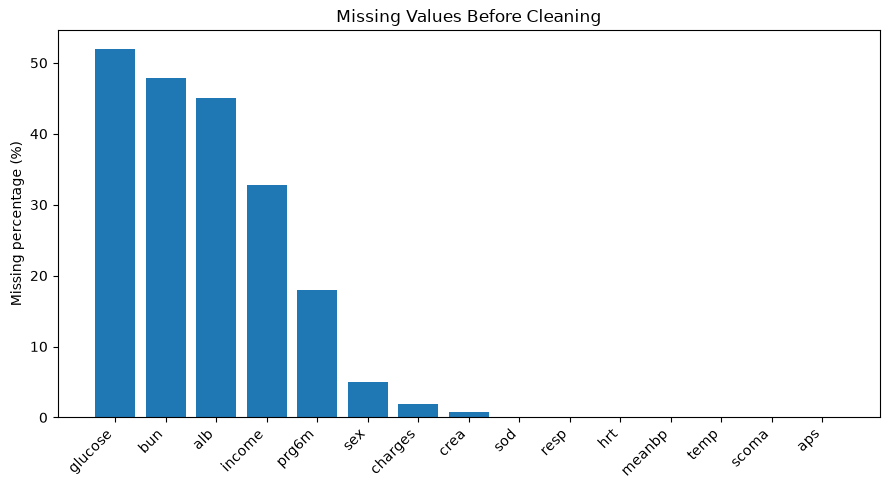

In [446]:
missing_plot = missing_before[missing_before["missing_values"] > 0].sort_values(
    "missing_percentage", ascending=False
)

plt.figure(figsize=(9, 5))
plt.bar(missing_plot.index, missing_plot["missing_percentage"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Missing percentage (%)")
plt.title("Missing Values Before Cleaning")
plt.tight_layout()
plt.show()

The missing values do not seem to come from repeated rows or from the same value being copied across consecutive observations. Most of the dataset is made of specific float variables with many decimal places, so it is very unlikely that many patients share exactly the same measurements.

In contrast, categorical fields such as `income` and `sex` are likely to repeat, however it's visible in the head of the dataset that some consecutive records share the same values.

For this reason, the missing values should be interpreted as genuinely absent entries rather than as a consequence of duplicated measurements across adjacent rows.

Since more than 50% of values of `glucose` column are missing we decided to drop it, instead for all others features having missing values because of the hints for the project and the fact that they have a limited amount of missing data we decided to impute their values. 

In [447]:
df = df.drop(columns=["glucose"])

In [448]:
completness = (1 - (missing_before["missing_values"].sum()) / (original_shape[0]*original_shape[1]))*100
print(f"The completness of the dataset is: {completness.round(2)}%")

The completness of the dataset is: 92.0%


## Range validation

Range checks applied:
- Inclusive numeric ranges (e.g. `age` 0–120, `scoma` 3–15, `adlsc` 0–7, `prg6m` 0-1, `aps` 0-299)
- Positive-value checks for variables that must be > 0 (e.g. `meanbp`, `hrt`, `resp`, `temp`, `crea`, `sod`, `bun`, `alb`)
- Non-negative checks (`num.co` >= 0, `charges` >= 0)

In [449]:
# Range rules derived from README
range_limits = {
    'age': (0, 120),
    'scoma': (3, 15),
    'adlsc': (0, 7),
    'prg6m': (0,1),
    'aps': (0,299)
}

# Columns that must be strictly > 0
gt_zero = [
    'meanbp','hrt','resp','temp','crea','sod','bun','alb'
]

# Columns that must be >= 0
non_negative = ['num.co','charges']

# Binary / categorical numeric expectations (0/1)
binary_cols = ['death','dementia','diabetes']

invalid_num = {}

# Inclusive-range checks
for col, (lo, hi) in range_limits.items():
    invalid_num[col] = ((df[col] < lo) | (df[col] > hi)).sum()

# >0 checks
for col in gt_zero:
    invalid_num[col] = (df[col] <= 0).sum()

# Non-negative checks
for col in non_negative:
    invalid_num[col] = (df[col] < 0).sum()

# 0/1 checks
for col in binary_cols:
    invalid_num[col] = ((df[col]!=0) & (df[col]!=1)).sum()

pd.Series(invalid_num).sort_values(ascending=False)

scoma       8356
hrt           83
resp          65
meanbp        51
adlsc          1
age            0
aps            0
prg6m          0
temp           0
crea           0
sod            0
bun            0
alb            0
num.co         0
charges        0
death          0
dementia       0
diabetes       0
dtype: int64

Columns (`hrt`, `resp`, `meanbp`, `adlsc`) have a few rows with invalid value, so we drop only those specific rows with observed values out of range.

In [450]:
cols = ["hrt", "resp", "meanbp"]

for col in cols:
    df = df[(df[col] > 0) | (df[col].isna())]

df = df[((df["adlsc"] >= 0) & (df["adlsc"] <= 7)) | (df["adlsc"].isna())]

print(f"The cleaned dataset by invalid range values contains {df.shape[0]} rows.")

The cleaned dataset by invalid range values contains 9001 rows.


The number of out-of-range values for `scoma` looks suspicious, so we analyze this column in more detail by looking at its distribution in a graph.

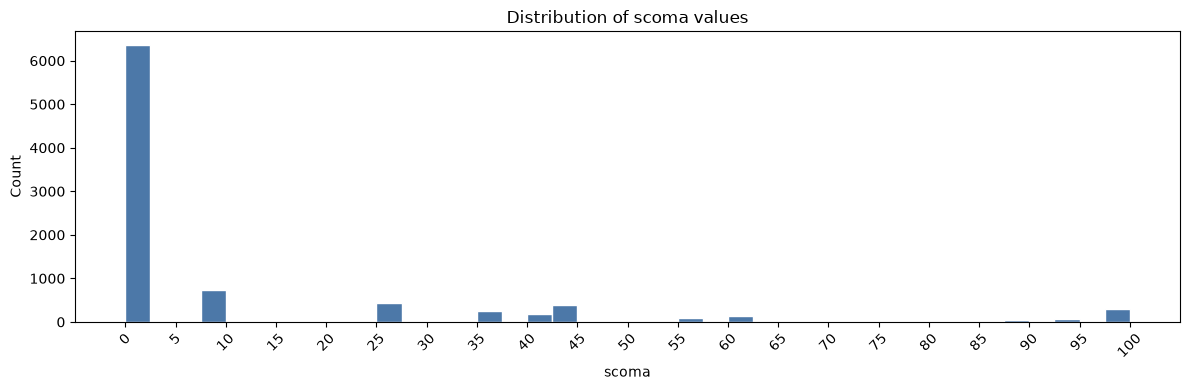

In [451]:
scoma_values = df["scoma"].dropna()

plt.figure(figsize=(12, 4))
plt.hist(scoma_values, bins=40, color="#4c78a8", edgecolor="white")
plt.xlabel("scoma")
plt.ylabel("Count")
plt.title("Distribution of scoma values")
plt.xticks(range(int(scoma_values.min()), int(scoma_values.max()) + 1, 5), rotation=45)
plt.tight_layout()
plt.show()

It is not clear what happened to the `scoma` data. Its valid range should be between 3 and 15, but the observed distribution does not match this expectation. It looks like some kind of rescaling may have been applied, but this is only an assumption. Since we do not have any additional information about it in the project specifications, we proceed by removing the column.

In [452]:
df = df.drop(columns=["scoma"])

We did not remove outliers because, in a clinical context, extreme values may represent real and critical patient conditions rather than measurement errors. Removing them could reduce the analysis’ ability to capture important signals for diagnosis. For this reason, outliers were retained, while only out of range values were excluded.

### One-Hot Encoding

Since this step will be needed both in the visualization section and later in the data analysis section, we perform it here.

Because the `dzgroup` column may contain more than one disease in the same cell, we cannot apply scikit-learn's `OneHotEncoder` directly, as it would treat each combination of diseases as a separate category.

Instead, we create one binary column for each possible disease, so that each patient can belong to multiple disease groups at the same time.

In [453]:
diseases = {
    "dz_ARF": "ARF",
    "dz_COPD": "COPD",
    "dz_CHF": "CHF",
    "dz_Liver_disease": "Cirrhosis",
    "dz_Coma": "Coma",
    "dz_Colon_cancer": "Colon cancer",
    "dz_Lung_cancer": "Lung cancer",
    "dz_MOSFM": "MOSF w/Malig",
    "dz_MOSFS": "MOSF w/Sepsis"
}

for col, pattern in diseases.items():
    df[col] = df["dzgroup"].str.contains(pattern, case=False).astype(int)

df = df.drop(columns=["dzgroup"])

analysis_df = df.copy()

I created a copy of the dataset before imputation, because it's the cleaned version of dataset that we will use for the classification pipeline

## Missing value imputation

Now that we have removed out of ranges values, we can impute missing values.
For numerical columns we use median as strategy since it's more robust to outliers and usually performs better than mean. Instead for categorical columns we use mode as strategy.

In [454]:
median_cols = ["bun", "alb", "crea", "prg6m","sod", "resp", "hrt", "meanbp", "temp", "aps","charges"]
df[median_cols] = df[median_cols].fillna(df[median_cols].median())

mode_cols = ["income","sex"]
df[mode_cols] = df[mode_cols].fillna(df[mode_cols].mode().iloc[0])

missing_after_imputation = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
})

missing_after_imputation[missing_after_imputation["missing_values"] > 0]

,missing_values,missing_percentage


Now there are no missing values left in the dataset, and it is fully cleaned. This imputation is only for the visualization part, using it also for the classfication pipeline would lead to data leakage since median and mode would be calculate on all dataset and not only on training set.

<hr>

## Data Visualization


At the beginning of this section we create one working dataframe, `df_viz`, copied from the cleaned dataframe. All visualization-specific transformations are added to this copy.

In [455]:
df_viz = df.copy()

### Comorbities and Death Rate by Disease

We aggregate rows with same disease to compute the mean number of comorbidities and the death rate.


In [456]:
records = []
for col, name in diseases.items():
    subset = df_viz[df_viz[col] == 1]
    records.append({
        "disease_group": col.lstrip("dz_").replace("_", " "),
        "mean_num_co": subset["num.co"].mean(),
        "mortality_rate": subset["death"].mean(),
    })

disease_stats = pd.DataFrame(records).sort_values("mortality_rate", ascending=False)
disease_stats["mortality_percent"] = disease_stats["mortality_rate"] * 100
disease_stats["survived_percent"] = 100 - disease_stats["mortality_percent"]

The following plot shows the average number of comorbidities on the left graph and death/surival rate on the right graph for each disease group.


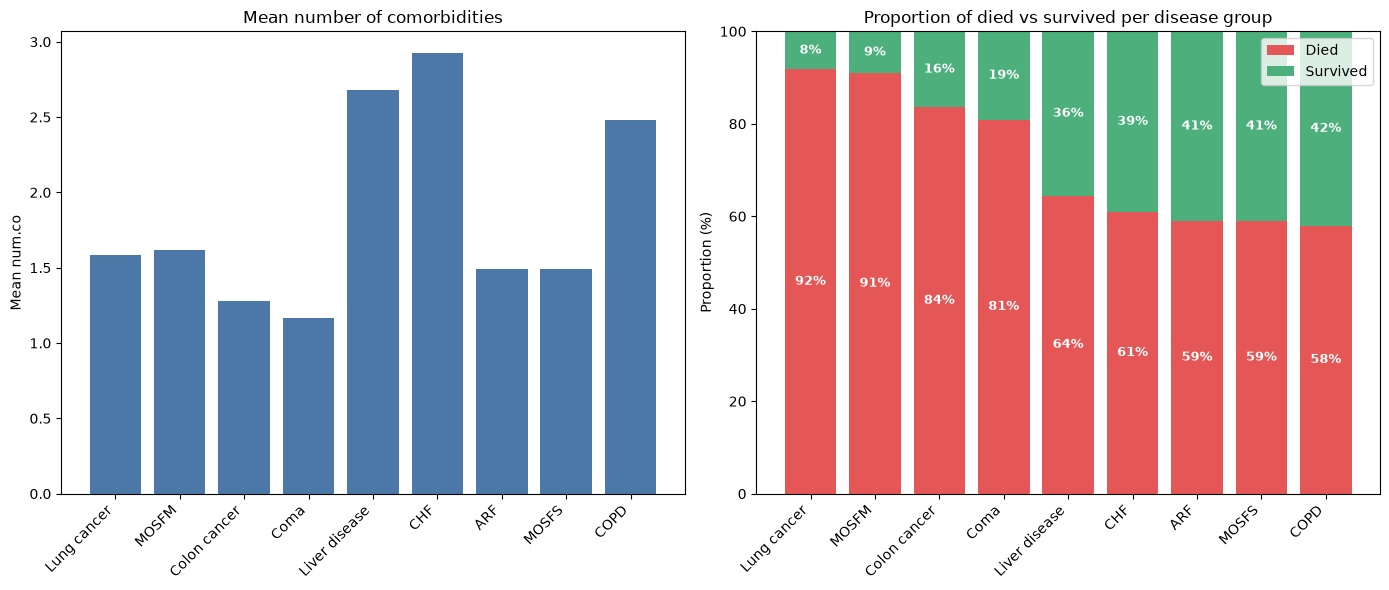

In [457]:
plt.figure(figsize=(14, 6))

x_labels = disease_stats["disease_group"].tolist()
x = range(len(x_labels))

# Left plot
plt.subplot(1, 2, 1)
plt.bar(x_labels, disease_stats["mean_num_co"], color="#4C78A8")
plt.title("Mean number of comorbidities")
plt.ylabel("Mean num.co")
plt.xticks(range(len(x_labels)), x_labels, rotation=45, ha="right")

# Right plot
plt.subplot(1, 2, 2)
plt.bar(x, disease_stats["mortality_percent"],
        label="Died", color="#E45756")
plt.bar(x, disease_stats["survived_percent"],
        bottom=disease_stats["mortality_percent"],
        label="Survived", color="#4DAF7C")

for i, (d, s) in enumerate(zip(disease_stats["mortality_percent"],
                                disease_stats["survived_percent"])):
    if d > 8:
        plt.text(i, d / 2, f"{d:.0f}%",
                 ha="center", va="center", fontsize=9,
                 color="white", fontweight="bold")
    if s > 8:
        plt.text(i, d + s / 2, f"{s:.0f}%",
                 ha="center", va="center", fontsize=9,
                 color="white", fontweight="bold")

plt.title("Proportion of died vs survived per disease group")
plt.ylabel("Proportion (%)")
plt.ylim(0, 100)
plt.xticks(range(len(x_labels)), x_labels, rotation=45, ha="right")
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

The charts reveal no clear positive correlation between number of comorbities and mortality rate. CHF and COPD, despite having the highest mean comorbidities
(~2.9 and ~2.5), show relatively low mortality (61% and 58%), while Lung cancer and MOSFM with far fewer comorbidities (~1.6) reach the highest death rates
in the cohort (92% and 91%).

This suggests that the intrinsic lethality of the primary disease drives outcomes more than the number of additional conditions.

### Correlation between income and cancer status with cost of hospitalization 

To answer this, we use two side by side box plots to compare the distributions of hospital charges. One groups the data by cancer status (colored by income), and the other groups by income (colored by cancer status).

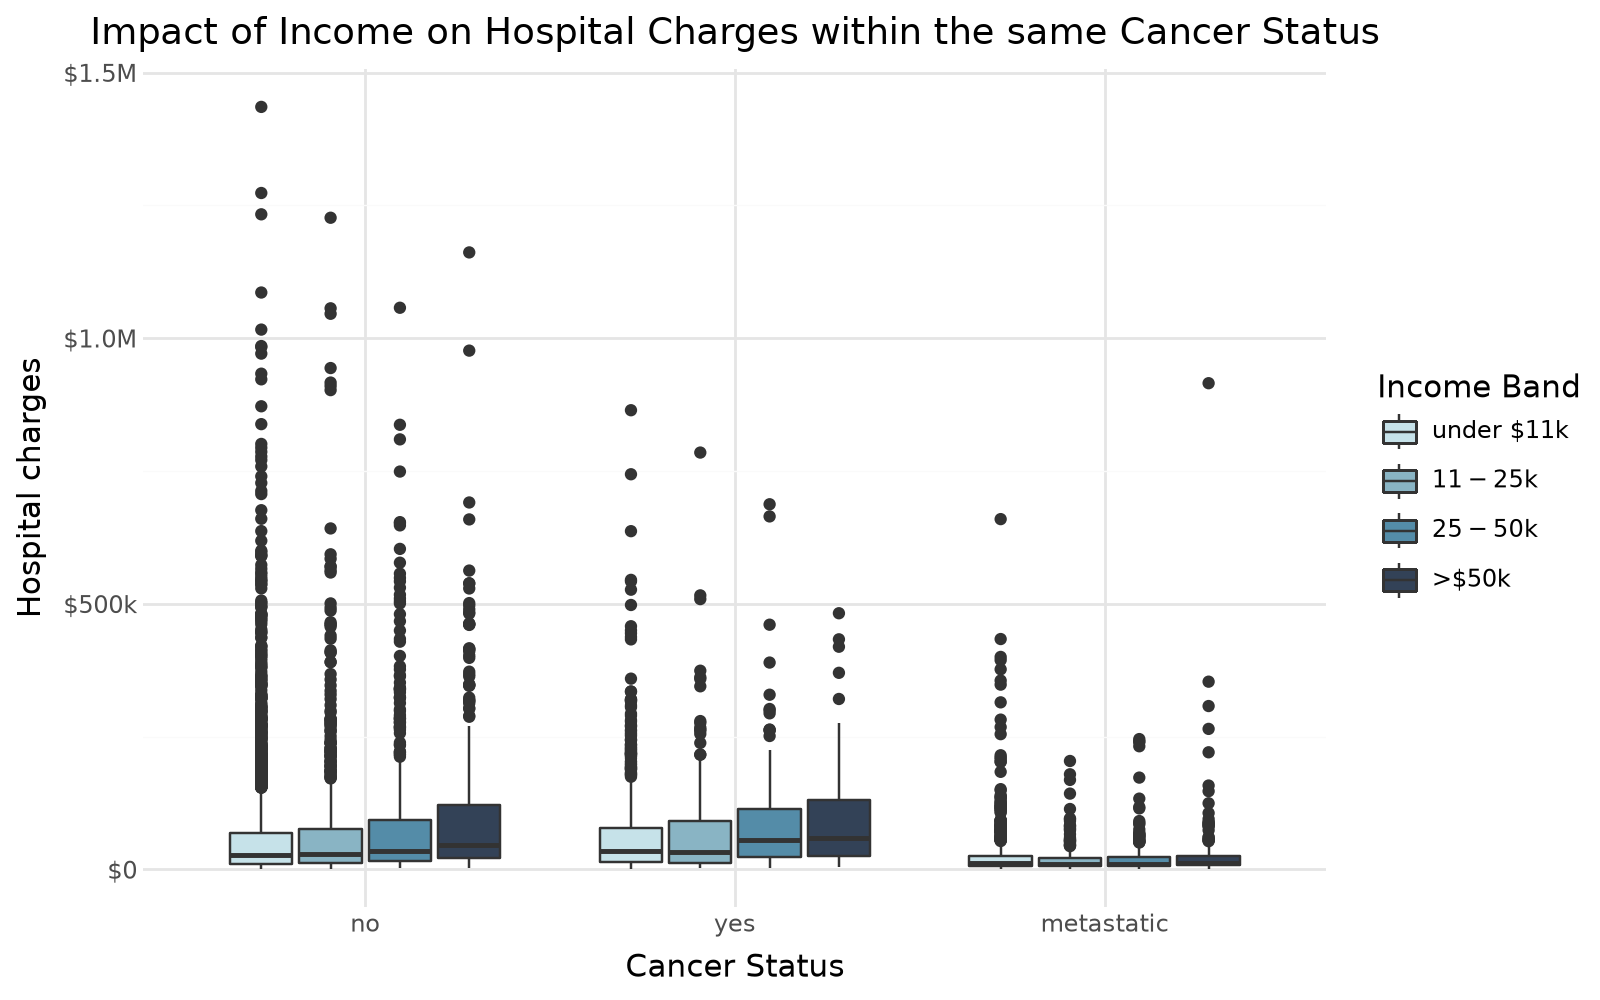

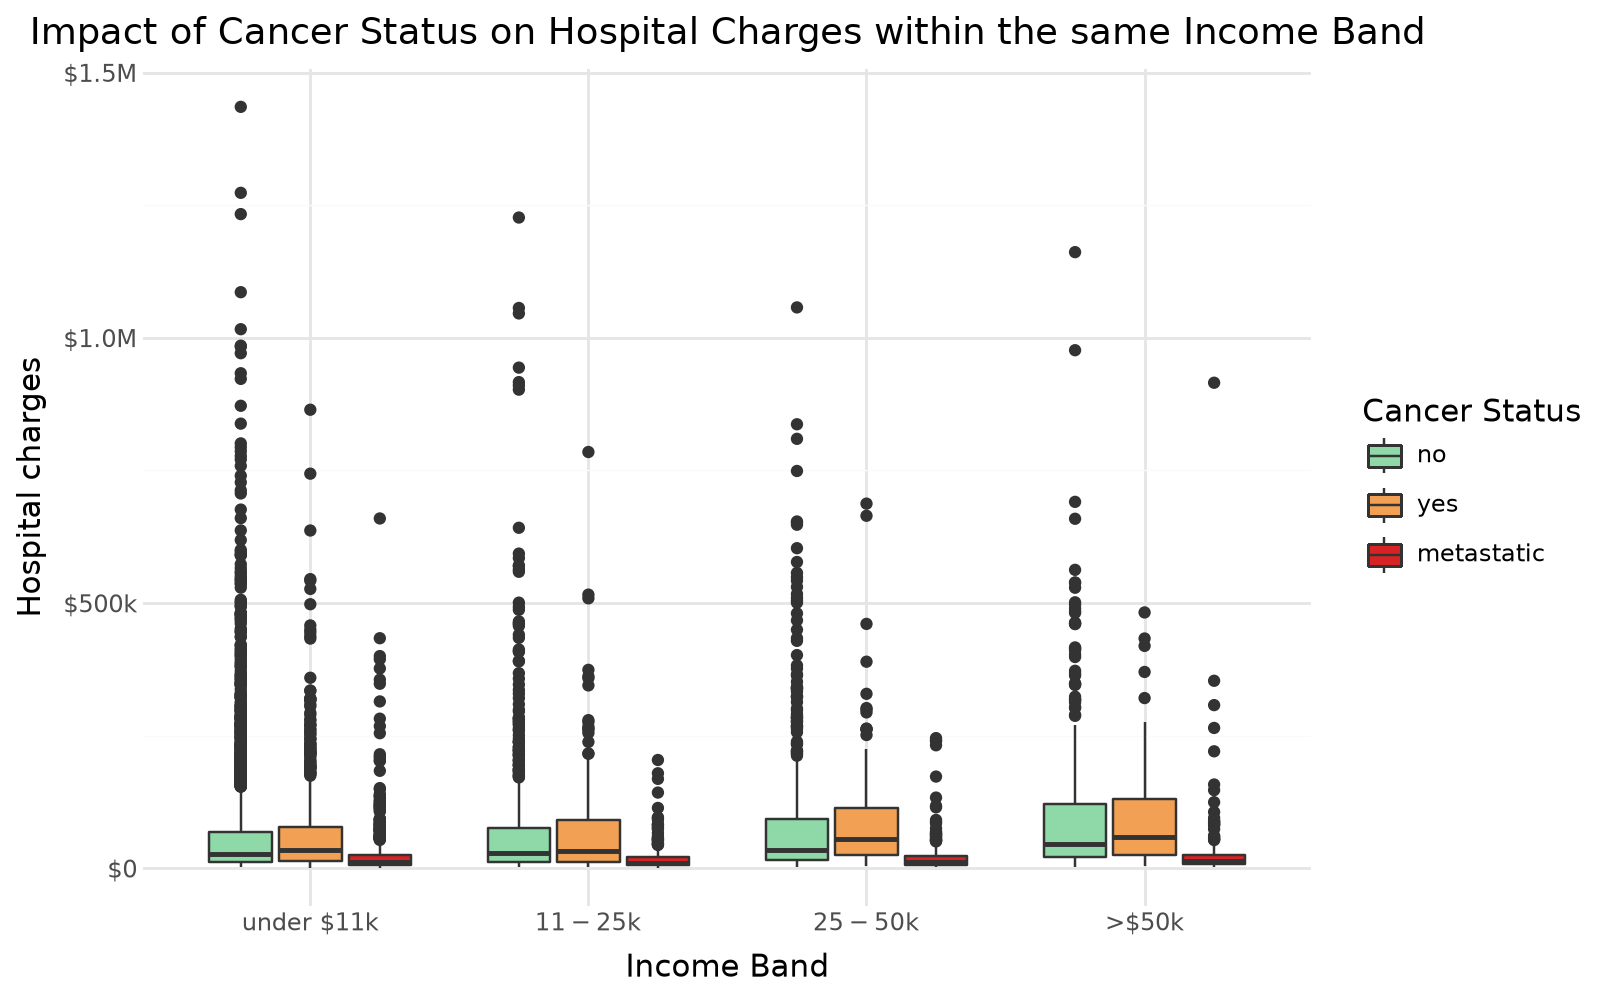

In [458]:
import pandas as pd
from plotnine import ggplot, aes, geom_boxplot, labs, theme_minimal, scale_fill_manual, scale_y_continuous, theme

charges_plot_df = df_viz.copy()
charges_plot_df["charges"] = pd.to_numeric(charges_plot_df["charges"], errors="coerce")
charges_plot_df = charges_plot_df.dropna(subset=["charges"])

income_colors = {
    "under $11k": "#C6E2E9", 
    "$11-$25k": "#89B4C4", 
    "$25-$50k": "#548CA8", 
    ">$50k": "#334257"
}
ca_colors = {"metastatic": "#D72323", "no": "#8FD9A8", "yes": "#F2A154"}

y_breaks = [0, 500000, 1000000, 1500000]
y_labels = ["$0", "$500k", "$1.0M", "$1.5M"]

p1 = (
    ggplot(charges_plot_df, aes(x="ca", y="charges", fill="income"))
    + geom_boxplot()
    + scale_fill_manual(values=income_colors)
    + scale_y_continuous(breaks=y_breaks, labels=y_labels)
    + labs(title="Impact of Income on Hospital Charges within the same Cancer Status", x="Cancer Status", y="Hospital charges", fill="Income Band")
    + theme_minimal()
    + theme(figure_size=(8, 5))
)
display(p1)

p2 = (
    ggplot(charges_plot_df, aes(x="income", y="charges", fill="ca"))
    + geom_boxplot()
    + scale_fill_manual(values=ca_colors)
    + scale_y_continuous(breaks=y_breaks, labels=y_labels)
    + labs(title="Impact of Cancer Status on Hospital Charges within the same Income Band", x="Income Band", y="Hospital charges", fill="Cancer Status")
    + theme_minimal()
    + theme(figure_size=(8, 5))
)
display(p2)


The plots show that hospital charges tend to increase with income. In addition, metastatic cancer cases generally show lower hospital charges than both non cancer patients and non-metastatic cancer patients. By contrast, patients with non metastatic cancer (`yes`) tend to have slightly higher charges than patients without cancer (`no`), although this difference appears fairly small.

### Physiological markers distributions at day 3 across disease groups

In [459]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

physiological_markers = [
    "meanbp", "hrt", "resp", "temp",
    "crea", "sod", "bun", "alb"
]

marker_labels = {
    "meanbp": "Mean arterial blood pressure (mmHg)",
    "hrt": "Heart rate (beats/min)",
    "resp": "Respiratory rate (breaths/min)",
    "temp": "Body temperature (°C)",
    "alb": "Serum albumin (g/dL)",
    "crea": "Serum creatinine (mg/dL)",
    "sod": "Serum sodium (mEq/L)",
    "bun": "Blood urea nitrogen (mg/dL)",
}

day3_df = df_viz[df_viz["hday"] == 3]

radio = widgets.RadioButtons(
    options=physiological_markers,
    value="meanbp",
    description="Physiological Marker:",
    layout=widgets.Layout(width="250px")
)

output = widgets.Output()

def plot_marker(change):
    marker = change["new"]
    marker_label = marker_labels.get(marker)

    with output:
        output.clear_output()

        groups = []
        labels = []

        for col in diseases.keys():
            values = day3_df.loc[day3_df[col] == 1, marker]
            if len(values) > 0:
                groups.append(values)
                labels.append(col.lstrip("dz_").replace("_"," "))

        plt.figure(figsize=(12, 6))
        plt.boxplot(groups, tick_labels=labels, patch_artist=True)
        plt.title(f"Distribution of {marker_label} at day 3 across disease groups")
        plt.xlabel("Disease group")
        plt.ylabel(marker_label)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

radio.observe(plot_marker, names="value")

ui = widgets.HBox(
    [radio, output],
    layout=widgets.Layout(align_items="flex-start", gap="20px")
)

display(ui)
plot_marker({"new": radio.value})

## Data Analysis

In this section we will use the `analysis_df` created in the cleaning part before imputing missing values. 

### Model Selection

Based on the project objective and the characteristics of the dataset, three classification models were selected to compare different modeling strategies and identify the most suitable one for the task.

- **Random Forest Classifier** was chosen because it is considered a strong default baseline for tabular data and can capture non linear relationships and feature interactions without requiring feature scaling.
- **k-NN** was included because it is a simple distance based model that works well on small to medium datasets and can adapt to irregular decision boundaries, making it useful as a non parametric comparison.
- **Logistic Regression** was selected mainly to include a linear model in the comparison, providing a fast and interpretable probabilistic baseline.

### Import Libraries
We import the necessary libraries for building the classification pipeline and evaluating it

In [460]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder,OrdinalEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

### Target variable analysis

Before splitting the data we inspect the class balance of `death`. An imbalanced target requires a stratified split and an appropriate scoring metric.

In [461]:
cleaned_positive_rate = analysis_df["death"].sum() / analysis_df.shape[0] * 100
print(f'The positive rate of death in the cleaned dataset is: {cleaned_positive_rate.round(2)}%')

The positive rate of death in the cleaned dataset is: 68.04%


### Feature selection

The target of this analysis is in hospital mortality, so the feature set was chosen to keep the clinical information that is available at prediction time.

- Physiological markers, together with `age` and `sex`, were kept because they are the basic variables of clinical assessment and therefore are essential for predicting mortality.
- The columns related to diseases and comorbidities, such as `num.co`, `diabetes`, and the other diagnosis indicators, were also kept because they provide relevant medical context for the patient.
- The column `income` was kept as well because this is a U.S. hospital dataset in a private healthcare setting, so it is reasonable to assume that higher income may be associated with better access to care and, indirectly, with better outcomes.
- The column `charges` was removed because it would create data leakage: it is not available at prediction time, since it is only known later and therefore cannot be used in a real 3 day prediction scenario.
- `prg6m` was retained because it is available at day 3 and may carry additional predictive signal as an expert model's survival estimate, though in a production setting its actual contribution to the model should be evaluated also on SUPPORT prognostic model performances.

In [462]:
analysis_df = analysis_df.drop(columns=["charges"])

### Train - Test split
We reserve **30 %** of the data for testing, and fix `random_state=42` for reproducibility.

In [463]:
X = analysis_df.drop(columns=["death"])
y = analysis_df["death"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Dataset positive class rate:  {y.mean():.2%}")
print(f"Remaining features:           {X.shape[1]}")
print(f"Train set positive rate:      {y_train.mean():.2%}")
print(f"Test  set positive rate:      {y_test.mean():.2%}")
print(f"Train size: {len(X_train)} — Test size: {len(X_test)}")

Dataset positive class rate:  68.04%
Remaining features:           28
Train set positive rate:      68.03%
Test  set positive rate:      68.05%
Train size: 6300 — Test size: 2701


### Imputing missing values

* `SimpleImputer` with median as strategy for numeric variables: `bun`, `alb`, `crea`, `prg6m`, `sod`, `resp`, `hrt`, `meanbp`, `temp`, `aps`
* `SimpleIMputer` with most frequent as strategy for categorical variables: `Income`,`sex`

In [464]:
cols_median_imputer = ['bun', 'alb', 'crea', 'prg6m', 'sod', 'resp', 'hrt', 'meanbp', 'temp', 'aps']

cols_mode_imputer = ["income","sex"]

### Categorical variables encoding

* `OneHotEncoder` for nominal variables: `Sex`,`Ca`
* `OrdinalEncoder` for ordinal variables: `Income`

`dzgroup` is a nominal variables but it has already been one hot encoded previously since we needed it also in the visualization part.

In [465]:
ordered_cat = [['under $11k', '$11-$25k', '$25-$50k', '>$50k']]
ord_columns = ['income']

oh_columns = ['sex', 'ca']

### Skewness correction

We first compute the skewness of numeric features, then apply `np.log1p` only to the selected columns with strong positive skewness. The transformation is implemented with `FunctionTransformer`, so it can be used inside a scikit-learn pipeline.

In [466]:
num_cols = X.select_dtypes("float").columns
skewness = X[num_cols].skew(numeric_only=True).sort_values(ascending=False)

threshold = 1.0
skewed_cols = skewness[skewness.abs() >= threshold].index.tolist()

print("Skewed numeric columns (|skew| >= 1):")
for col in skewed_cols:
    print(col)

Skewed numeric columns (|skew| >= 1):
alb
crea
bun


### Feature scaling

For **Logistic Regression** and **k-NN**, we standardize the numeric features with a `StandardScaler`  because both models are sensitive to distances between features.

In [467]:
cols_to_scale = [
    "age",
    "num.co",
    "meanbp",
    "hrt",
    "resp",
    "temp",
    "crea",
    "sod",
    "adlsc",
    "hday",
    "aps",
    "bun",
    "alb",
    "prg6m"
]

### Models Pipelines Creation and Hyperparameter Tuning via Cross-Validation

We will create distinct pipelines for our selected models (Logistic Regression, Random Forest, and k-NN) and tune their hyperparameters using 5 fold `GridSearchCV`. By embedding preprocessing steps inside the pipelines, we strictly prevent data leakage during cross-validation.

**Metric Selection (ROC-AUC)**

We chose `roc_auc` over standard accuracy due to the dataset's significant class imbalance (`death` is ≈68% positive). ROC-AUC evaluates the models' ability to distinguish between classes across all thresholds, providing a much more robust evaluation than accuracy, which would be misleading.

**Threshold Selection: 0.30**

In hospital mortality prediction, a false negative is more costly than a false positive.
Using a threshold of 0.30 increases recall for the positive class, reducing the risk of missing high-risk patients.
This choice is appropriate for early triage and alerting, where it is better to flag an at risk patient for review than to overlook a critical case. A higher threshold would only make sense if the prediction triggered a highly consequential action requiring very high certainty.

In [468]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING_METRIC = 'roc_auc'
THRESHOLD = 0.30

non_skewed_num_cols = [c for c in cols_to_scale if c not in skewed_cols]

# Binary/integer columns that need no transformation (dzARF, dzCOPD, etc.)
binary_cols = [c for c in X_train.columns
               if c not in skewed_cols + non_skewed_num_cols + ord_columns + oh_columns]

#### Model 1: Logistic Regression

In [469]:
preprocessor_lr = ColumnTransformer([
    ('skewed_scaled_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('log',     FunctionTransformer(np.log1p, validate=False)),
        ('scaler',  StandardScaler()),
    ]), skewed_cols),

    ('num_scaled_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
    ]), non_skewed_num_cols),

    ('ordinal_cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(categories=ordered_cat)),
    ]), ord_columns),

    ('nominal_cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), oh_columns),

    ('binary', 'passthrough', binary_cols),
], remainder='drop')

model = Pipeline([
    ("preprocessing", preprocessor_lr),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
}

grid_search_lr = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring=SCORING_METRIC,
    cv=CV,
    n_jobs=-1,
    refit=True,
)

grid_search_lr.fit(X_train, y_train)

print(f"Best CV ROC-AUC: {grid_search_lr.best_score_:.4f}")
print("Best parameter for Logistic Regression:")
print(f"  C: {grid_search_lr.best_params_['model__C']}")


best_lr = grid_search_lr.best_estimator_
y_proba = best_lr.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= THRESHOLD).astype(int)

print()
print("Refitted model")
print(f"ROC-AUC score: {roc_auc_score(y_test,y_proba)}")

print()
print(classification_report(y_test, y_pred))

conf_matrix = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["Actual 0 (survived)", "Actual 1 (died)"],
    columns=["Predicted 0 (survived)", "Predicted 1 (died)"],
)

conf_matrix

Best CV ROC-AUC: 0.7997
Best parameter for Logistic Regression:
  C: 1

Refitted model
ROC-AUC score: 0.7966383683206468

              precision    recall  f1-score   support

           0       0.80      0.21      0.33       863
           1       0.72      0.97      0.83      1838

    accuracy                           0.73      2701
   macro avg       0.76      0.59      0.58      2701
weighted avg       0.75      0.73      0.67      2701



,Predicted 0 (survived),Predicted 1 (died)
Actual 0 (survived),180,683
Actual 1 (died),46,1792


The Logistic Regression achieves a Test ROC-AUC of 0.797, very close to the best-performing model. 
At the 0.30 threshold, the model correctly identifies 97.6% of deceased patients (recall = 0.98 
for class 1), at the cost of a very low recall for survivors (0.21), meaning most surviving 
patients are incorrectly predicted as deceased. This behavior is expected and acceptable given 
the chosen threshold, which deliberately prioritizes sensitivity over specificity in a 
mortality-prediction context.

#### Model 2: Random Forest

In [470]:
preprocessor_rf = ColumnTransformer([
    ('skewed_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('log',     FunctionTransformer(np.log1p, validate=False)),
    ]), skewed_cols),

    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
    ]), non_skewed_num_cols),

    ('ordinal_cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(categories=ordered_cat)),
    ]), ord_columns),

    ('nominal_cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), oh_columns),

    ('binary', 'passthrough', binary_cols),
], remainder='drop')

model = Pipeline([
    ("preprocessing", preprocessor_rf),
    ("model", RandomForestClassifier(random_state=42, class_weight="balanced_subsample"))
])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [8, 12, None],
    "model__min_samples_leaf": [1, 2, 5]
}

grid_search_rf = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring=SCORING_METRIC,
    cv=CV,
    n_jobs=-1,
    refit=True,
)

grid_search_rf.fit(X_train, y_train)

print(f"Best CV ROC-AUC: {grid_search_rf.best_score_:.4f}")
print("Best parameters for Random Forest:")
print(f"  Max Depth: {grid_search_rf.best_params_['model__max_depth']}")
print(f"  N Estimators: {grid_search_rf.best_params_['model__n_estimators']}")
print(f"  Min Samples Leaf: {grid_search_rf.best_params_['model__min_samples_leaf']}")


best_rf = grid_search_rf.best_estimator_
y_proba = best_rf.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= THRESHOLD).astype(int)

print()
print("Refitted model")
print(f"ROC-AUC score: {roc_auc_score(y_test,y_proba)}")

print()
print(classification_report(y_test, y_pred))

conf_matrix = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["Actual 0 (survived)", "Actual 1 (died)"],
    columns=["Predicted 0 (survived)", "Predicted 1 (died)"],
)

conf_matrix

Best CV ROC-AUC: 0.8004
Best parameters for Random Forest:
  Max Depth: 12
  N Estimators: 300
  Min Samples Leaf: 5

Refitted model
ROC-AUC score: 0.797600419620803

              precision    recall  f1-score   support

           0       0.75      0.25      0.38       863
           1       0.73      0.96      0.83      1838

    accuracy                           0.73      2701
   macro avg       0.74      0.61      0.60      2701
weighted avg       0.74      0.73      0.69      2701



,Predicted 0 (survived),Predicted 1 (died)
Actual 0 (survived),219,644
Actual 1 (died),74,1764


The Random Forest is the top-performing model, reaching a Test ROC-AUC of 0.798. The use of 
class_weight="balanced_subsample" helps the model handle the class imbalance, and the best 
hyperparameters selected by GridSearchCV (max_depth=12, n_estimators=300, min_samples_leaf=2) 
suggest the model benefits from moderate depth to avoid overfitting. The performance profile at 
threshold 0.30 is similar to Logistic Regression in terms of recall for the positive class, 
while overall accuracy and the macro-average F1-score are slightly higher.

#### Model 3: k-NN

In [471]:
preprocessor_knn = ColumnTransformer([
    ('skewed_scaled_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('log',     FunctionTransformer(np.log1p, validate=False)),
        ('scaler',  StandardScaler()),
    ]), skewed_cols),

    ('num_scaled_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
    ]), non_skewed_num_cols),

    ('ordinal_cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(categories=ordered_cat)),
    ]), ord_columns),

    ('nominal_cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), oh_columns),

    ('binary', 'passthrough', binary_cols),
], remainder='drop')

model = Pipeline([
    ("preprocessing", preprocessor_knn),
    ("model", KNeighborsClassifier())
])

param_grid = {
    "model__n_neighbors": [3, 5, 7, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

grid_search_knn = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring=SCORING_METRIC,
    cv=CV,
    n_jobs=-1,
    refit=True,
)

grid_search_knn.fit(X_train, y_train)

print(f"Best CV ROC-AUC: {grid_search_knn.best_score_:.4f}")
print("Best parameters for k-NN:")
print(f"  N Neighbors: {grid_search_knn.best_params_['model__n_neighbors']}")
print(f"  Weights: {grid_search_knn.best_params_['model__weights']}")
print(f"  P: {grid_search_knn.best_params_['model__p']}")

best_knn = grid_search_knn.best_estimator_
y_proba = best_knn.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= THRESHOLD).astype(int)

print()
print("Refitted model")
print(f"ROC-AUC score: {roc_auc_score(y_test,y_proba)}")

print()
print(classification_report(y_test, y_pred))

conf_matrix = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["Actual 0 (survived)", "Actual 1 (died)"],
    columns=["Predicted 0 (survived)", "Predicted 1 (died)"],
)

conf_matrix

Best CV ROC-AUC: 0.7555
Best parameters for k-NN:
  N Neighbors: 15
  Weights: uniform
  P: 2

Refitted model
ROC-AUC score: 0.7522601270714679

              precision    recall  f1-score   support

           0       0.78      0.16      0.26       863
           1       0.71      0.98      0.82      1838

    accuracy                           0.72      2701
   macro avg       0.74      0.57      0.54      2701
weighted avg       0.73      0.72      0.64      2701



,Predicted 0 (survived),Predicted 1 (died)
Actual 0 (survived),135,728
Actual 1 (died),39,1799


The k-NN model shows the weakest performance, with a Test ROC-AUC of 0.752, notably lower than 
the other two models. Even at the 0.30 threshold, the recall for surviving patients is only 0.16, 
the lowest among the three models. This is likely due to the high-dimensional feature space, with 28 features including encoded categoricals and physiological markers on different scales, 
which makes distance-based similarity less effective. The optimal k=15 with uniform weights and 
Euclidean distance (p=2) suggests the model needs a large neighborhood to be stable, which is 
consistent with a noisy, high dimensional input space.

Model Performance Summary:


,Model,CV ROC-AUC,Test ROC-AUC
1,Random Forest,0.8004,0.7976
0,Logistic Regression,0.7997,0.7966
2,k-NN,0.7555,0.7523


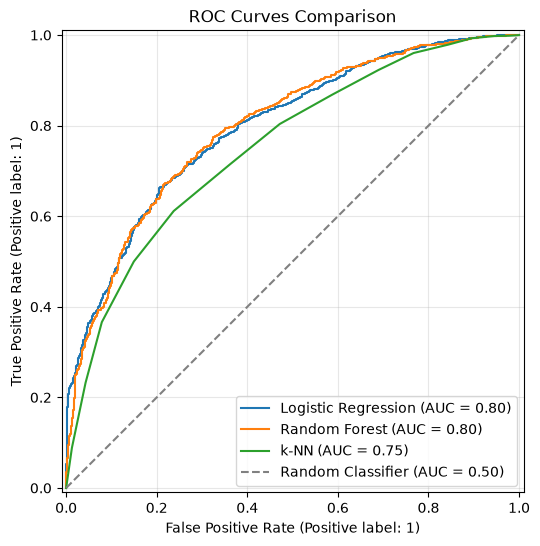

In [472]:
results_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "k-NN"],
    "CV ROC-AUC": [
        grid_search_lr.best_score_,
        grid_search_rf.best_score_,
        grid_search_knn.best_score_
    ],
    "Test ROC-AUC": [
        roc_auc_score(y_test, best_lr.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, best_knn.predict_proba(X_test)[:, 1])
    ]
})

print("Model Performance Summary:")
display(results_df.round(4).sort_values(by="Test ROC-AUC", ascending=False))

fig, ax = plt.subplots(figsize=(8, 6))

# Logistic Regression
RocCurveDisplay.from_estimator(
    best_lr, X_test, y_test, name="Logistic Regression", ax=ax
)

# Random Forest
RocCurveDisplay.from_estimator(
    best_rf, X_test, y_test, name="Random Forest", ax=ax
)

# k-NN
RocCurveDisplay.from_estimator(
    best_knn, X_test, y_test, name="k-NN", ax=ax
)

# baseline 0.5
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")

plt.title("ROC Curves Comparison")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

### Conclusion
Based on metrics evaluations and ROC curves, the model comparison yields the following observations:

Overall, Random Forest is the best candidate for production because it gives the best trade-off between performance and robustness, with the highest ROC-AUC and a strong ability to capture non linear relationships and feature interactions. Logistic Regression performs almost as well and remains the best fallback option when interpretability, transparency, and simplicity are more important than a small gain in predictive power. k-NN is the least suitable model here, since its performance is clearly lower and it is more sensitive to the feature space structure.